In [1]:
import numpy as np 
import matplotlib.pyplot as plt

In [3]:
class Reaction_Difusion_FDM:

    a: np.ndarray
    b: np.ndarray

    def __init__(self, l, d, p, dx, dt, size):

        dl = d / (p * l**2)
        lb = (dl * dt) / dx**2

        gamma1 = 1. - 0.5 * dt + 2. * lb
        gamma2 = 1. + 0.5 * dt - 2. * lb

        a = np.zeros((size**2, size**2))
        b = np.zeros((size**2, size**2))

        for i in range(size**2):

            if i == 0:

                # CONDIÇÃO DE CONTORNO: VERTICE - BAIXO, ESQUERDA
                a[i,i], b[i,i] = 6, -6
                a[i,i+1], b[i,i+1] = -4, 4
                a[i,i+2], b[i,i+2] = 1, -1
                a[i,i+size], b[i,i+size] = -4, 4
                a[i,i+2*size], b[i, i+2*size] = 1, -1

            elif i == size-1:

                # CONDIÇÃO DE CONTORNO: VERTICE - BAIXO, DIREITA
                a[i,i], b[i,i] = 6, -6
                a[i,i-1], b[i,i-1] = -4, 4
                a[i,i-2], b[i,i-2] = 1, -1
                a[i,i+size], b[i,i+size] = -4, 4
                a[i,i+2*size], b[i,i+2*size] = 1, -1

            elif i == size**2 - size:

                # CONDIÇÃO DE CONTORNO: VERTICE - CIMA, ESQUERDA
                a[i,i], b[i,i] = 6, -6
                a[i,i+1], b[i,i+1] = -4, 4
                a[i,i+2], b[i,i+2] = 1, -1
                a[i,i-size], b[i,i-size] = -4, 4
                a[i,i-2*size], b[i, i-2*size] = 1, -1

            elif i == size**2 - 1:

                # CONDIÇÃO DE CONTORNO: VERTICE - CIMDA, DIREITA
                a[i,i], b[i,i] = 6, -6
                a[i,i-1], b[i,i-1] = -4, 4
                a[i,i-2], b[i,i-2] = 1, -1
                a[i,i-size], b[i,i-size] = -4, 4
                a[i,i-2*size], b[i,i-2*size] = 1, -1

            # CONDIÇÃO DE CONTORNO: BAIXO
            elif i > 0 and i < size-1:

                a[i, i], b[i,i] = 3 / (4. * dx), -3 / (4. * dx)
                a[i, i+size], b[i,i+size] =  -4 / (4. * dx), 4 / (4. * dx)
                a[i, i+2*size], b[i,i+2*size] =  1 / (4. * dx), - 1 / (4. * dx)

            # CONDIÇÃO DE CONTORNO: CIMA
            elif i > size**2 - size - 1 and i < size**2 - 1:

                a[i, i], b[i,i] = 3 / (4. * dx), -3 / (4. * dx)
                a[i, i-size], b[i,i-size] =  -4 / (4. * dx), 4 / (4. * dx)
                a[i, i-2*size], b[i,i-2*size] =  1 / (4. * dx), - 1 / (4. * dx)


            # CONDIÇÃO DE CONTORNO: ESQUERDA
            elif i%size == 0:

                a[i, i], b[i,i] = 3 / (4. * dx), -3 / (4. * dx)
                a[i, i+1], b[i,i+1] =  -4 / (4. * dx), 4 / (4. * dx)
                a[i, i+2], b[i,i+2] =  1 / (4. * dx), - 1 / (4. * dx)

            # CONDIÇÃO DE CONTORNO: DIREITA
            elif i%size == size-1:

                a[i, i], b[i,i] = 3 / (4. * dx), -3 / (4. * dx)
                a[i, i-1], b[i,i-1] =  -4 / (4. * dx), 4 / (4. * dx)
                a[i, i-2], b[i,i-2] =  1 / (4. * dx), - 1 / (4. * dx)

            # PONTOS INTERNOS
            else:

                a[i,i], b[i,i] = gamma1, gamma2
                a[i,i+1], b[i,i+1] = -0.5 * lb, 0.5 * lb
                a[i,i+size], b[i,i+size] = -0.5 * lb, 0.5 * lb
                a[i,i-1], b[i,i-1] = -0.5 * lb, 0.5 * lb
                a[i,i-size], b[i,i-size] = -0.5 * lb, 0.5 * lb

        self.a = a
        self.b = b

    def __call__(self, x):

        dir = self.b @ x
        return np.linalg.solve(self.a, dir)

In [4]:
class Reaction_Difusion_FDM_02:

    a: np.ndarray
    b: np.ndarray

    def __init__(self, D, rho, dx, dt, size):

        lb = (D * dt) / dx**2

        gamma1 = 1. - 0.5 * rho * dt + 2. * lb
        gamma2 = 1. + 0.5 * rho * dt - 2. * lb

        a = np.zeros((size**2, size**2))
        b = np.zeros((size**2, size**2))

        for i in range(size**2):

            if i == 0:

                # CONDIÇÃO DE CONTORNO: VERTICE - BAIXO, ESQUERDA
                a[i,i], b[i,i] = 6, -6
                a[i,i+1], b[i,i+1] = -4, 4
                a[i,i+2], b[i,i+2] = 1, -1
                a[i,i+size], b[i,i+size] = -4, 4
                a[i,i+2*size], b[i, i+2*size] = 1, -1

            elif i == size-1:

                # CONDIÇÃO DE CONTORNO: VERTICE - BAIXO, DIREITA
                a[i,i], b[i,i] = 6, -6
                a[i,i-1], b[i,i-1] = -4, 4
                a[i,i-2], b[i,i-2] = 1, -1
                a[i,i+size], b[i,i+size] = -4, 4
                a[i,i+2*size], b[i,i+2*size] = 1, -1

            elif i == size**2 - size:

                # CONDIÇÃO DE CONTORNO: VERTICE - CIMA, ESQUERDA
                a[i,i], b[i,i] = 6, -6
                a[i,i+1], b[i,i+1] = -4, 4
                a[i,i+2], b[i,i+2] = 1, -1
                a[i,i-size], b[i,i-size] = -4, 4
                a[i,i-2*size], b[i, i-2*size] = 1, -1

            elif i == size**2 - 1:

                # CONDIÇÃO DE CONTORNO: VERTICE - CIMDA, DIREITA
                a[i,i], b[i,i] = 6, -6
                a[i,i-1], b[i,i-1] = -4, 4
                a[i,i-2], b[i,i-2] = 1, -1
                a[i,i-size], b[i,i-size] = -4, 4
                a[i,i-2*size], b[i,i-2*size] = 1, -1

            # CONDIÇÃO DE CONTORNO: BAIXO
            elif i > 0 and i < size-1:

                a[i, i], b[i,i] = 3 / (4. * dx), -3 / (4. * dx)
                a[i, i+size], b[i,i+size] =  -4 / (4. * dx), 4 / (4. * dx)
                a[i, i+2*size], b[i,i+2*size] =  1 / (4. * dx), - 1 / (4. * dx)

            # CONDIÇÃO DE CONTORNO: CIMA
            elif i > size**2 - size - 1 and i < size**2 - 1:

                a[i, i], b[i,i] = 3 / (4. * dx), -3 / (4. * dx)
                a[i, i-size], b[i,i-size] =  -4 / (4. * dx), 4 / (4. * dx)
                a[i, i-2*size], b[i,i-2*size] =  1 / (4. * dx), - 1 / (4. * dx)

            # CONDIÇÃO DE CONTORNO: ESQUERDA
            elif i%size == 0:

                a[i, i], b[i,i] = 3 / (4. * dx), -3 / (4. * dx)
                a[i, i+1], b[i,i+1] =  -4 / (4. * dx), 4 / (4. * dx)
                a[i, i+2], b[i,i+2] =  1 / (4. * dx), - 1 / (4. * dx)

            # CONDIÇÃO DE CONTORNO: DIREITA
            elif i%size == size-1:

                a[i, i], b[i,i] = 3 / (4. * dx), -3 / (4. * dx)
                a[i, i-1], b[i,i-1] =  -4 / (4. * dx), 4 / (4. * dx)
                a[i, i-2], b[i,i-2] =  1 / (4. * dx), - 1 / (4. * dx)

            # PONTOS INTERNOS
            else:

                a[i,i], b[i,i] = gamma1, gamma2
                a[i,i+1], b[i,i+1] = -0.5 * lb, 0.5 * lb
                a[i,i+size], b[i,i+size] = -0.5 * lb, 0.5 * lb
                a[i,i-1], b[i,i-1] = -0.5 * lb, 0.5 * lb
                a[i,i-size], b[i,i-size] = -0.5 * lb, 0.5 * lb

        self.a = a
        self.b = b

    def __call__(self, x):

        dir = self.b @ x
        return np.linalg.solve(self.a, dir)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros físicos e numéricos
D, R = 0.01, 0.5
K, M = 2, 1
size = 50
n_steps = 100

# Discretização do espaço e construção da malha
x = y = np.linspace(0, 1, size)
t = np.linspace(0, 1, n_steps)
dx = x[1]
dt = t[1]
X, Y = np.meshgrid(x, y)

# Condição inicial: modo cosseno 
u0 = np.cos(K * np.pi * X) * np.cos(M * np.pi * Y)

# Evolução temporal com a classe
solver = Reaction_Difusion_FDM(20, D, R, dx, dt, size)

u = np.zeros((n_steps, size ** 2))
u[0] = u0.ravel()
for i in range(1, n_steps): u[i] = solver(u[i-1])
U_num = u.reshape(n_steps, size, size)

In [ ]:
# Solução analítica
def u_exact(t):
    
    lam = R - D * np.pi**2 * (K**2 + M**2)
    return u0 * np.exp(lam * t)

U_ana = np.zeros((n_steps, size, size))
for i in range(n_steps): U_ana[i] = u_exact(i * dt)

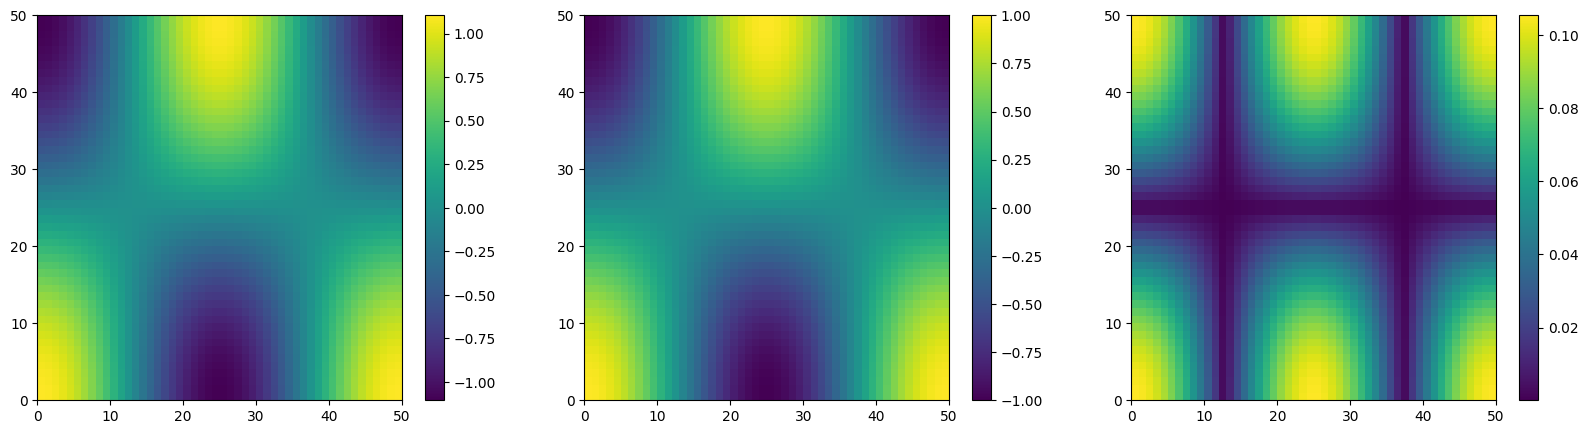

In [9]:
idx = 10

fig, ax = plt.subplots(ncols = 3, figsize = (20, 5))

p0 = ax[0].pcolormesh(U_num[idx])
p1 = ax[1].pcolormesh(U_ana[idx])
p2 = ax[2].pcolormesh(np.abs(U_num[idx] - U_ana[idx]))

plt.colorbar(p0)
plt.colorbar(p1)
plt.colorbar(p2)
plt.show()

In [73]:
domain = np.zeros((n_steps * size * size, 3))

for i in range(n_steps):

    for j in range(size):

        for k in range(size):

            domain[i * size**2 + j * size + k] = [t[i], x[j], x[k]]

In [74]:
np.savez('../Dados/Numericos/data_001.npz', parameters = [D, R, K, M], target = U_num, input = domain)